In [1]:

import numpy as np
import matplotlib.pyplot as plt
import qutip as qt


In [2]:
from qudit_nh_design import *

from matplotlib import rc, rcParams
params = {'legend.fontsize': 15, "axes.labelsize": 15}
rc('text', usetex=True)
rc('xtick', labelsize=14)
rc('ytick', labelsize=14)
rcParams.update(params)

Quantum object: dims=[[3], [3]], shape=(3, 3), type='oper', dtype=Dense, isherm=True
Qobj data =
[[1. 0. 0.]
 [0. 1. 0.]
 [0. 0. 0.]] Quantum object: dims=[[3], [3]], shape=(3, 3), type='oper', dtype=Dense, isherm=True
Qobj data =
[[0. 0. 0.]
 [0. 0. 0.]
 [0. 0. 1.]]


In [2]:
Q = np.zeros([3,3])
Q[2,2]=1
Q=qt.Qobj(Q)
P=1-Q
print(P,Q)

Quantum object: dims=[[3], [3]], shape=(3, 3), type='oper', dtype=Dense, isherm=True
Qobj data =
[[1. 0. 0.]
 [0. 1. 0.]
 [0. 0. 0.]] Quantum object: dims=[[3], [3]], shape=(3, 3), type='oper', dtype=Dense, isherm=True
Qobj data =
[[0. 0. 0.]
 [0. 0. 0.]
 [0. 0. 1.]]


## 1 - Three examples of non-Hermitian dynamics
### 1.1 - Single steady-state, high entropy

In [128]:
N=2
h, J, Omega= 1,8.0, 1.0
tf = 20
nstep = 400
tvec = np.linspace(0,tf,nstep+1)
rate = nstep/tf
dt=tf/nstep
#--- full Hamiltonian with measurements
single_body_terms = [[h, ('x', 0, 1), None],[Omega, ('x', 1, 2), None] ]
two_body_terms=[[J,('x', 1, 2), ('x', 1, 2)]]
H_qutrit = build_hamiltonian(N,single_body_terms, two_body_terms)

#--- target effective Hamiltonian
heff, lambda1, lambda2 = h, -1j*Omega**2/rate/2, -1j*J**2/rate/2
print(f"effective paramters: lambda_1={lambda1:.2f}, lambda_2={lambda2:.2f}")
single_body_eff = [[heff, ('x', 0, 1), None], [lambda1, ('p-', 0, 1), None] ]
two_body_eff=[[lambda2,('p-', 0, 1), ('p-', 0, 1)]]
H_qeff = build_hamiltonian(N,single_body_eff, two_body_eff,d=2)

print(H_qutrit.isherm,H_qeff.isherm)
psi0 = qt.basis([3]*N,n=[0,1]*(N//2))
psi0_eff = qt.basis([2]*N,n=[0,1]*(N//2))
#psi0 = qt.tensor([(qt.basis(3,n=1)+qt.basis(3,n=0)).unit()]*N)
#psi0_eff = qt.tensor([(qt.basis(2,n=1)+qt.basis(2,n=0)).unit()]*N)

Z01 = embedded_pauli('z',0,1)
N01 = qt.Qobj([[0,0,0],[0,1,0],[0,0,0]])
n01 = qt.Qobj([[0,0],[0,1]])
print(Z01)
e_evo = [embed_on_site(Z01,j,N) for j in range(N)]
print(e_evo)
ZZ_evo = [qt.tensor([N01,N01])]
print(ZZ_evo)
e_evo_eff = [embed_on_site(qt.sigmaz(),j,N,d=2) for j in range(N)]
ZZ_evo_eff = [qt.tensor([n01,n01])]

print(qt.expect(e_evo,psi0))
options={'progress':False, 'store_states':True}

effective paramters: lambda_1=-0.00-0.03j, lambda_2=-0.00-1.60j
True False
Quantum object: dims=[[3], [3]], shape=(3, 3), type='oper', dtype=Dense, isherm=True
Qobj data =
[[ 1.  0.  0.]
 [ 0. -1.  0.]
 [ 0.  0.  0.]]
[Quantum object: dims=[[3, 3], [3, 3]], shape=(9, 9), type='oper', dtype=Dia, isherm=True
Qobj data =
[[ 1.  0.  0.  0.  0.  0.  0.  0.  0.]
 [ 0.  1.  0.  0.  0.  0.  0.  0.  0.]
 [ 0.  0.  1.  0.  0.  0.  0.  0.  0.]
 [ 0.  0.  0. -1.  0.  0.  0.  0.  0.]
 [ 0.  0.  0.  0. -1.  0.  0.  0.  0.]
 [ 0.  0.  0.  0.  0. -1.  0.  0.  0.]
 [ 0.  0.  0.  0.  0.  0.  0.  0.  0.]
 [ 0.  0.  0.  0.  0.  0.  0.  0.  0.]
 [ 0.  0.  0.  0.  0.  0.  0.  0.  0.]], Quantum object: dims=[[3, 3], [3, 3]], shape=(9, 9), type='oper', dtype=Dia, isherm=True
Qobj data =
[[ 1.  0.  0.  0.  0.  0.  0.  0.  0.]
 [ 0. -1.  0.  0.  0.  0.  0.  0.  0.]
 [ 0.  0.  0.  0.  0.  0.  0.  0.  0.]
 [ 0.  0.  0.  1.  0.  0.  0.  0.  0.]
 [ 0.  0.  0.  0. -1.  0.  0.  0.  0.]
 [ 0.  0.  0.  0.  0.  0.  0.  

In [129]:

res = time_evo(H_qutrit,psi0,tvec,P,N,measured_sites=[j for j in range(N)],e_ops=e_evo+ZZ_evo, 
               force_proj=True,options=options)
'''
res_rand = time_evo(H_qutrit,psi0,trand,P,N,measured_sites=[j for j in range(N)],e_ops=e_evo, 
               force_proj=True,options={'uniform_dt':False, 'progress':False})
'''

res2 = time_evo(H_qeff,psi0_eff,tvec,P,N,measured_sites=[],e_ops=e_evo_eff+ZZ_evo_eff, options=options)

0.11729944868044309 0.020000000000000004


'\nplt.plot(tvec,res.expect[0])\nplt.plot(tvec,res.expect[1])\n\nplt.plot(trand,res_rand.expect[0],\'-.\')\nplt.plot(trand,res_rand.expect[1],\'-.\')\n\nplt.plot(tvec,res2.expect[0],\'--\')\nplt.plot(tvec,res2.expect[1],\'--\')\nplt.xlabel(r"time $t h_x$")\n'

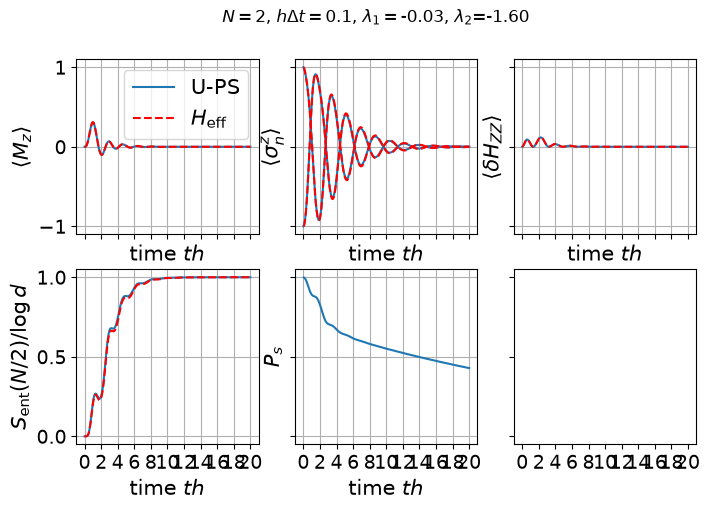

In [130]:

fig,ax = plt.subplots(nrows=2,ncols=3,sharex=True, sharey='row')
fig.set_size_inches([8,5])
fig.suptitle(rf"$N={N}$, $h\Delta t=0.1$, $\lambda_1=${lambda1.imag:.2f}, $\lambda_2$={lambda2.imag:.2f}")
ax[0,0].plot(tvec,sum(res.expect[:-1])/2,label='U-PS')
#ax[0].plot(trand,sum(res_rand.expect)/2,'g-.',label='R-PS')
ax[0,0].plot(tvec,sum(res2.expect[:-1])/2,'r--',label=r'$H_{\rm eff}$')
ax[1,0].set_xlabel(r'time $t h$')
ax[1,1].set_xlabel(r'time $t h$')
ax[0,0].set_xlabel(r'time $t h$')
ax[0,0].set_ylabel(r'$\langle M_z \rangle$')
ax[0,0].legend()
ax[0,0].grid()
ax[0,0].set_xticks(np.arange(0,22,2))

ax[0,1].grid()
ax[0,1].plot(tvec,np.array(res.expect[0:-1:2]).mean(axis=0),label='U-PS',c='C0')
ax[0,1].plot(tvec,np.array(res.expect[1:-1:2]).mean(axis=0),label='U-PS',c='C0')
#ax[1].plot(trand,res_rand.expect[0],'g-.',label='R-PS')
#ax[1].plot(trand,res_rand.expect[1],'g-.',label='R-PS')
ax[0,1].plot(tvec,np.array(res2.expect[0:-1:2]).mean(axis=0),'r--',label=r'$H_{\rm eff}$')
ax[0,1].plot(tvec,np.array(res2.expect[1:-1:2]).mean(axis=0),'r--',label=r'$H_{\rm eff}$')
ax[0,1].set_xlabel(r'time $t h$')
ax[0,1].set_ylabel(r'$\langle \sigma^z_n \rangle$')


ax[0,2].grid()
ax[0,2].plot(tvec,np.array(res.expect[-1]),label='U-PS',c='C0')

#ax[1].plot(trand,res_rand.expect[0],'g-.',label='R-PS')
#ax[1].plot(trand,res_rand.expect[1],'g-.',label='R-PS')
ax[0,2].plot(tvec,np.array(res2.expect[-1]),'r--',label=r'$H_{\rm eff}$')

ax[0,2].set_xlabel(r'time $t h$')
ax[0,2].set_ylabel(r'$\langle \delta H_{ZZ} \rangle$')
print(np.max(np.array(res.expect[-1])), dt**2*Omega**2*J)

ax[1,0].plot(tvec,get_entanglement(res.states,[j for j in range(N//2)])/np.log(2))
ax[1,0].plot(tvec,get_entanglement(res2.states,[j for j in range(N//2)])/np.log(2),'r--')
ax[1,0].grid()
ax[1,0].set_ylabel(r'$S_{\rm ent}(N/2)/\log d$')

ax[1,1].plot(tvec[1:],np.cumprod(np.array(res.measurement_outcomes[1:]))) 
ax[1,1].set_ylabel(r'$P_s$')
ax[1,1].grid()
'''
plt.plot(tvec,res.expect[0])
plt.plot(tvec,res.expect[1])

plt.plot(trand,res_rand.expect[0],'-.')
plt.plot(trand,res_rand.expect[1],'-.')

plt.plot(tvec,res2.expect[0],'--')
plt.plot(tvec,res2.expect[1],'--')
plt.xlabel(r"time $t h_x$")
'''
#fig.savefig(f'N{N}_entangled.pdf',bbox_inches='tight')

### 1.2 Doubly degenerate steady state.

In [135]:
N=2
h, J, Omega= 1,8, 10
tf = 20
nstep = 400
tvec = np.linspace(0,tf,nstep+1)
rate = nstep/tf
trand = poisson_times(tf,rate)
dt=tf/nstep
#--- full Hamiltonian with measurements
single_body_terms = [[h, ('x', 0, 1), None],[Omega, ('x', 1, 2), None] ]
two_body_terms=[[J,('x', 1, 2), ('x', 1, 2)]]
H_qutrit = build_hamiltonian(N,single_body_terms, two_body_terms)

#--- target effective Hamiltonian
heff, lambda1, lambda2 = h, -1j*Omega**2/rate/2, -1j*J**2/rate/2
print(f"effective paramters: lambda_1={lambda1:.2f}, lambda_2={lambda2:.2f}")
single_body_eff = [[heff, ('x', 0, 1), None], [lambda1, ('p-', 0, 1), None] ]
two_body_eff=[[lambda2,('p-', 0, 1), ('p-', 0, 1)]]
H_qeff = build_hamiltonian(N,single_body_eff, two_body_eff,d=2)

# sanity check that the full Hamiltonian is hermitian while the effective one is not
print(f"Hermiticity of full qutrit Hamiltonian:{H_qutrit.isherm}, effective Hamiltonian:{H_qeff.isherm}")

psi0 = qt.basis([3]*N,n=[0,1]*(N//2))
psi0_eff = qt.basis([2]*N,n=[0,1]*(N//2))

#local observable      
Z01 = embedded_pauli('z',0,1)
e_evo = [embed_on_site(Z01,j,N) for j in range(N)]
e_evo_eff = [embed_on_site(qt.sigmaz(),j,N,d=2) for j in range(N)]
      
options={'progress':False, 'store_states':True}

res = time_evo(H_qutrit,psi0,tvec,P,N,measured_sites=[j for j in range(N)],e_ops=e_evo+ZZ_evo, 
               force_proj=True,options=options)

res2 = time_evo(H_qeff,psi0_eff,tvec,P,N,measured_sites=[],e_ops=e_evo_eff+ZZ_evo_eff, options=options)

effective paramters: lambda_1=-0.00-2.50j, lambda_2=-0.00-1.60j
Hermiticity of full qutrit Hamiltonian:True, effective Hamiltonian:False


0.020036885669824065 2.0000000000000004


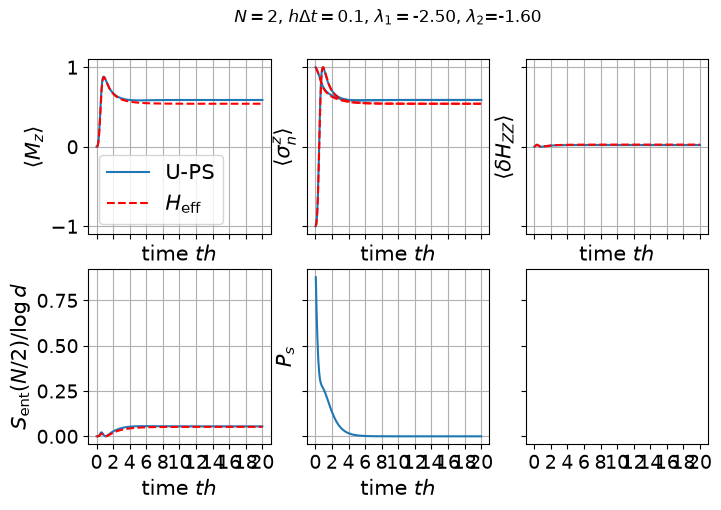

In [136]:

fig,ax = plt.subplots(nrows=2,ncols=3,sharex=True, sharey='row')
fig.set_size_inches([8,5])
fig.suptitle(rf"$N={N}$, $h\Delta t={tf/nstep:.1f}$, $\lambda_1=${lambda1.imag:.2f}, $\lambda_2$={lambda2.imag:.2f}")
ax[0,0].plot(tvec,sum(res.expect[:-1])/2,label='U-PS')
#ax[0].plot(trand,sum(res_rand.expect)/2,'g-.',label='R-PS')
ax[0,0].plot(tvec,sum(res2.expect[:-1])/2,'r--',label=r'$H_{\rm eff}$')
ax[1,0].set_xlabel(r'time $t h$')
ax[1,1].set_xlabel(r'time $t h$')
ax[0,0].set_xlabel(r'time $t h$')
ax[0,0].set_ylabel(r'$\langle M_z \rangle$')
ax[0,0].legend()
ax[0,0].grid()
ax[0,0].set_xticks(np.arange(0,22,2))

ax[0,1].grid()
ax[0,1].plot(tvec,np.array(res.expect[0:-1:2]).mean(axis=0),label='U-PS',c='C0')
ax[0,1].plot(tvec,np.array(res.expect[1:-1:2]).mean(axis=0),label='U-PS',c='C0')
#ax[1].plot(trand,res_rand.expect[0],'g-.',label='R-PS')
#ax[1].plot(trand,res_rand.expect[1],'g-.',label='R-PS')
ax[0,1].plot(tvec,np.array(res2.expect[0:-1:2]).mean(axis=0),'r--',label=r'$H_{\rm eff}$')
ax[0,1].plot(tvec,np.array(res2.expect[1:-1:2]).mean(axis=0),'r--',label=r'$H_{\rm eff}$')
ax[0,1].set_xlabel(r'time $t h$')
ax[0,1].set_ylabel(r'$\langle \sigma^z_n \rangle$')


ax[0,2].grid()
ax[0,2].plot(tvec,np.array(res.expect[-1]),label='U-PS',c='C0')

#ax[1].plot(trand,res_rand.expect[0],'g-.',label='R-PS')
#ax[1].plot(trand,res_rand.expect[1],'g-.',label='R-PS')
ax[0,2].plot(tvec,np.array(res2.expect[-1]),'r--',label=r'$H_{\rm eff}$')

ax[0,2].set_xlabel(r'time $t h$')
ax[0,2].set_ylabel(r'$\langle \delta H_{ZZ} \rangle$')
print(np.mean(np.array(res.expect[-1])),Omega**2*J*dt**2)


ax[1,0].plot(tvec,get_entanglement(res.states,[j for j in range(N//2)])/np.log(3))
ax[1,0].plot(tvec,get_entanglement(res2.states,[j for j in range(N//2)])/np.log(2),'r--')
ax[1,0].grid()
ax[1,0].set_ylabel(r'$S_{\rm ent}(N/2)/\log d$')

ax[1,1].plot(tvec[1:],np.cumprod(np.array(res.measurement_outcomes[1:]))) 
ax[1,1].set_ylabel(r'$P_s$')
ax[1,1].grid()
#fig.savefig('N{N}_oscillatory.pdf',bbox_inches='tight')

### 1.3 Single steady state, low entropy

In [59]:
N=6
h, J, Omega= 1,3.5, 5.1*np.sqrt(2)
tf = 15
nstep = 150
tvec = np.linspace(0,tf,nstep+1)
rate = nstep/tf
trand = poisson_times(tf,rate)

#--- full Hamiltonian with measurements
single_body_terms = [[h, ('x', 0, 1), None],[Omega, ('x', 1, 2), None] ]
two_body_terms=[[J,('x', 1, 2), ('x', 1, 2)]]
H_qutrit = build_hamiltonian(N,single_body_terms, two_body_terms)

#--- target effective Hamiltonian
heff, lambda1, lambda2 = h, -1j*Omega**2/rate/4, -1j*J**2/rate/4
print(f"effective paramters: lambda_1={lambda1:.2f}, lambda_2={lambda2:.2f}")
single_body_eff = [[heff, ('x', 0, 1), None], [2*lambda1, ('p-', 0, 1), None] ]
two_body_eff=[[2*lambda2,('p-', 0, 1), ('p-', 0, 1)]]
H_qeff = build_hamiltonian(N,single_body_eff, two_body_eff,d=2)

print(H_qutrit.isherm,H_qeff.isherm)
psi0 = qt.basis([3]*N,n=[0,1]*(N//2))
psi0_eff = qt.basis([2]*N,n=[0,1]*(N//2))

Z01 = embedded_pauli('z',0,1)
print(Z01)
e_evo = [embed_on_site(Z01,j,N) for j in range(N)]
e_evo_eff = [embed_on_site(qt.sigmaz(),j,N,d=2) for j in range(N)]
print(qt.expect(e_evo,psi0))
options={'progress':False}

res = time_evo(H_qutrit,psi0,tvec,P,N,measured_sites=[j for j in range(N)],e_ops=e_evo, 
               force_proj=True,options=options)

#res_rand = time_evo(H_qutrit,psi0,trand,P,N,measured_sites=[j for j in range(N)],e_ops=e_evo, 
#               force_proj=True,options={'uniform_dt':False, 'progress':False})

res2 = time_evo(H_qeff,psi0_eff,tvec,P,N,measured_sites=[],e_ops=e_evo_eff, options=options)

effective paramters: lambda_1=-0.00-1.30j, lambda_2=-0.00-0.31j
True False
Quantum object: dims=[[3], [3]], shape=(3, 3), type='oper', dtype=Dense, isherm=True
Qobj data =
[[ 1.  0.  0.]
 [ 0. -1.  0.]
 [ 0.  0.  0.]]
[1.0, -1.0, 1.0, -1.0, 1.0, -1.0]


TypeError: Input is not a quantum object

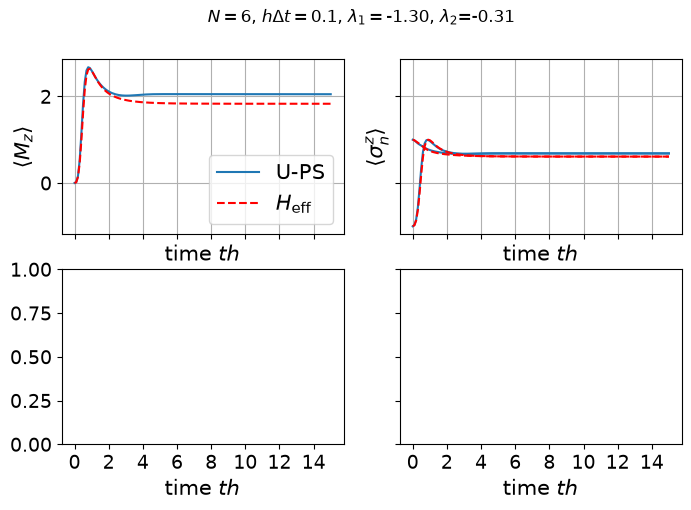

In [60]:

fig,ax = plt.subplots(nrows=2,ncols=2,sharex=True, sharey='row')
fig.set_size_inches([8,5])
fig.suptitle(rf"$N={N}$, $h\Delta t={tf/nstep:.1f}$, $\lambda_1=${lambda1.imag:.2f}, $\lambda_2$={lambda2.imag:.2f}")
ax[0,0].plot(tvec,sum(res.expect)/2,label='U-PS')
#ax[0].plot(trand,sum(res_rand.expect)/2,'g-.',label='R-PS')
ax[0,0].plot(tvec,sum(res2.expect)/2,'r--',label=r'$H_{\rm eff}$')
ax[1,0].set_xlabel(r'time $t h$')
ax[1,1].set_xlabel(r'time $t h$')
ax[0,0].set_xlabel(r'time $t h$')
ax[0,0].set_ylabel(r'$\langle M_z \rangle$')
ax[0,0].legend()
ax[0,0].grid()
ax[0,0].set_xticks(np.arange(0,16,2))

ax[0,1].grid()
ax[0,1].plot(tvec,np.array(res.expect[0::2]).mean(axis=0),label='U-PS',c='C0')
ax[0,1].plot(tvec,np.array(res.expect[1::2]).mean(axis=0),label='U-PS',c='C0')
#ax[1].plot(trand,res_rand.expect[0],'g-.',label='R-PS')
#ax[1].plot(trand,res_rand.expect[1],'g-.',label='R-PS')
ax[0,1].plot(tvec,np.array(res2.expect[0::2]).mean(axis=0),'r--',label=r'$H_{\rm eff}$')
ax[0,1].plot(tvec,np.array(res2.expect[1::2]).mean(axis=0),'r--',label=r'$H_{\rm eff}$')
ax[0,1].set_xlabel(r'time $t h$')
ax[0,1].set_ylabel(r'$\langle \sigma^z_n \rangle$')



ax[1,0].plot(tvec,get_entanglement(res.states,[j for j in range(N//2)])/np.log(3))
ax[1,0].plot(tvec,get_entanglement(res2.states,[j for j in range(N//2)])/np.log(2),'r--')
ax[1,0].grid()
ax[1,0].set_ylabel(r'$S_{\rm ent}(N/2)/\log d$')

ax[1,1].plot(tvec[1:],np.cumprod(np.array(res.measurement_outcomes[1:]))) 
ax[1,1].set_ylabel(r'$P_s$')
ax[1,1].grid()

#fig.savefig('N{N}_separable.pdf',bbox_inches='tight')

## 2 - Phase diagram

In [8]:
N = 4
h=1
ns=100
lambda1_list=np.linspace(0.01,2.5,ns)
lambda2_list=np.linspace(0.01,2.5,ns)
gs_multiplicity4 = []
gs_entropy4 = []
gs_gap4 =[]
for lam1 in lambda1_list:
    for lam2 in lambda2_list:
        heff, lambda1, lambda2 = h, -1j*lam1, -1j*lam2
        #print(f"effective paramters: lambda_1={lambda1:.2f}, lambda_2={lambda2:.2f}")
        single_body_eff = [[heff, ('x', 0, 1), None], [2*lambda1, ('p-', 0, 1), None] ]
        two_body_eff=[[2*lambda2,('p-', 0, 1), ('p-', 0, 1)]]
        H_qeff = build_hamiltonian(N,single_body_eff, two_body_eff,d=2)
        res = nh_stationary_states(H_qeff,N, tol=1e-8,d=2)
        gs_multiplicity4.append(res.degeneracy)
        gs_entropy4.append(np.array(res.entanglement_entropies).mean())      
        gs_gap4.append(-(res.steady_eigenvalue[-1]-res.steady_eigenvalue[0]).imag)

In [3]:
gs_multiplicity = np.loadtxt("../results/Data/Data/N8_gsmultiplicity_lam2.5_ns100.csv",delimiter=',')
gs_gap = np.loadtxt("../results/Data/Data/N8_gsgap_lam2.5_ns100.csv",delimiter=',')
gs_entropy = np.loadtxt("../results/Data/Data/N8_gsentropy_lam2.5_ns100.csv",delimiter=',')
ns=100
lambda1_list=np.linspace(0.01,2.5,ns)/2
lambda2_list=np.linspace(0.01,2.5,ns)/2

C:\Users\matte\AppData\Local\Temp\ipykernel_25860\3768946791.py:9: UserWarning: The following kwargs were not used by contour: 'label'
  ax[0].contour(2*X,2*Y,np.array(gs_multiplicity2).reshape([ns,ns]),levels=1,colors='C0',label='N=2')


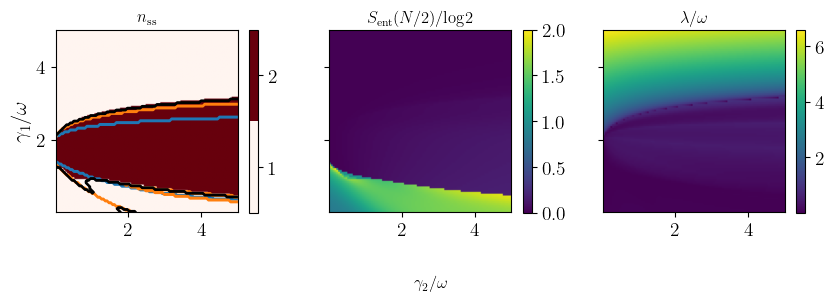

In [50]:
N=8
fig, ax = plt.subplots(ncols=3,sharex=True, sharey=True)
fig.set_size_inches([10,3.5])
fig.supxlabel(r'$\gamma_2/\omega$')
ax[0].set_ylabel(r'$\gamma_1/\omega$')
im=ax[0].imshow(np.array(gs_multiplicity).reshape([ns,ns]),origin='lower',
                extent=[0.02,5,0.02,5],cmap='Reds')
X,Y = np.meshgrid(lambda2_list,lambda1_list)
ax[0].contour(2*X,2*Y,np.array(gs_multiplicity2).reshape([ns,ns]),levels=1,colors='C0')
ax[0].contour(2*X,2*Y,np.array(gs_multiplicity4).reshape([ns,ns]),levels=1,colors='C1')
ax[0].contour(2*X,2*Y,np.array(gs_multiplicity6).reshape([ns,ns]),levels=2,colors='k')
fig.colorbar(im,ax=ax[0],shrink=0.68,boundaries=[0.5,1.5,2.5],values=[1,2],ticks=[1,2])
ax[0].set_title(r'$n_{\rm ss}$')
im=ax[1].imshow(np.array(gs_entropy).reshape([ns,ns])/np.log(2),origin='lower',
                extent=[0.02,5,0.02,5],vmin=0,vmax=2)
fig.colorbar(im,ax=ax[1],shrink=0.68,ticks=[0,0.5,1.0,1.5,2.0])
ax[1].set_title(r'$S_{\rm ent}(N/2)/{\rm log}2$')

im=ax[2].imshow((np.array(gs_gap)).reshape([ns,ns])/np.log(2),origin='lower',
                extent=[0.02,5,0.02,5])
fig.colorbar(im,ax=ax[2],shrink=0.68)
ax[2].set_title(r'$\lambda/\omega$')

fig.savefig(f'phase_diagram_N{N}.pdf',bbox_inches='tight')

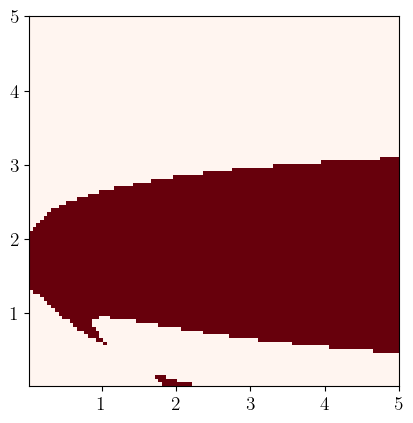

In [77]:
plt.imshow(np.array(gs_multiplicity6).reshape([ns,ns]),origin='lower',
                extent=[0.02,5,0.02,5],cmap='Reds')

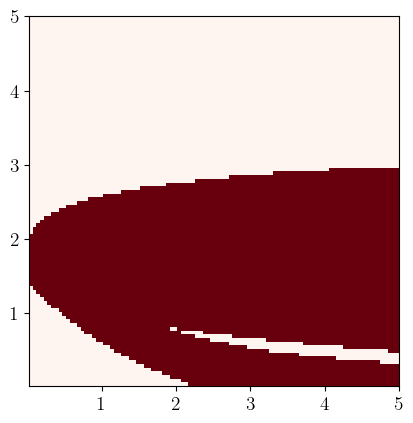

In [9]:
plt.imshow(np.array(gs_multiplicity4).reshape([ns,ns]),origin='lower',
                extent=[0.02,5,0.02,5],cmap='Reds')

## Full stocastic dynamics

In [39]:
N=4
h, J, Omega= 1,4, 0.5
tf = 15
nstep = 150
tvec = np.linspace(0,tf,nstep+1)
rate = nstep/tf
trand = poisson_times(tf,rate)

#--- full Hamiltonian with measurements
single_body_terms = [[h, ('x', 0, 1), None],[Omega, ('x', 1, 2), None] ]
two_body_terms=[[J,('x', 1, 2), ('x', 1, 2)]]
H_qutrit = build_hamiltonian(N,single_body_terms, two_body_terms)

heff, lambda1, lambda2 = h, -1j*Omega**2/rate/4, -1j*J**2/rate/4
print(f"effective paramters: lambda_1={lambda1:.2f}, lambda_2={lambda2:.2f}")
psi0 = qt.basis([3]*N,n=[0,1]*(N//2))

Z01 = embedded_pauli('z',0,1)
e_evo = [embed_on_site(Z01,j,N) for j in range(N)]

res=run_trajectories(H_qutrit, psi0, tvec, P,N, measured_sites=[j for j in range(N)], 
                     ntraj = 100, e_ops = e_evo,n_jobs=10)

effective paramters: lambda_1=0.00-0.01j, lambda_2=0.00-0.40j


In [41]:
res=run_trajectories(H_qutrit, psi0, tvec, P,N, measured_sites=[j for j in range(N)], 
                     ntraj = 100, e_ops = e_evo,n_jobs=10)

Running 100 trajectories on 10 workers...


Trajectories: 100%|█████████████████████████████████████████████████████████████| 100/100 [00:29<00:00,  3.42traj/s]


In [10]:
def success_until_t(ps):
    for ntr, traj in enumerate(ps):
        for ist, pst in enumerate(traj):
            if not pst:
                traj[ist+1:]=False
                continue
        ps[ntr] = traj
    return ps

[]

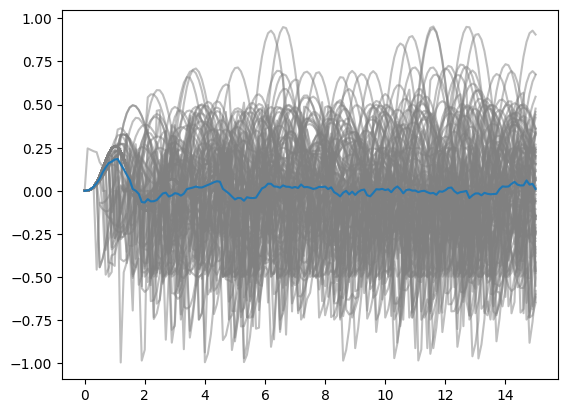

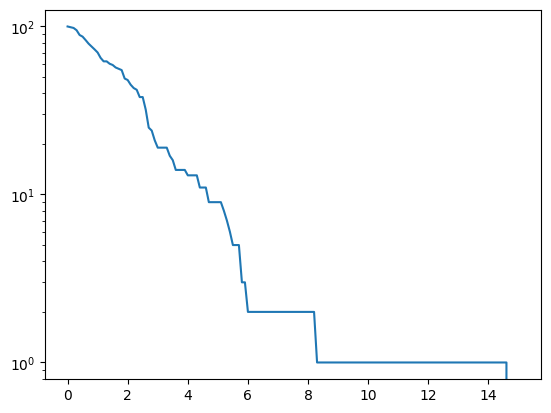

In [42]:
plt.plot(tvec,np.array(res.expect_traj).mean(axis=0).T,c='gray',alpha=0.5);
plt.plot(tvec,np.array(res.expect_mean).mean(axis=0))
plt.figure()
plt.plot(tvec,np.array(success_until_t(res.proj_traj)).sum(axis=0))
plt.semilogy()

## Comparison between diffeernt points in the phase diagram

effective paramters: lambda_1=-0.00-0.00j, lambda_2=-0.00-0.05j
effective paramters: lambda_1=-0.00-0.01j, lambda_2=-0.00-0.05j
effective paramters: lambda_1=-0.00-0.03j, lambda_2=-0.00-0.05j
effective paramters: lambda_1=-0.00-0.05j, lambda_2=-0.00-0.05j
effective paramters: lambda_1=-0.00-0.08j, lambda_2=-0.00-0.05j
effective paramters: lambda_1=-0.00-0.11j, lambda_2=-0.00-0.05j
effective paramters: lambda_1=-0.00-0.15j, lambda_2=-0.00-0.05j
effective paramters: lambda_1=-0.00-0.20j, lambda_2=-0.00-0.05j
effective paramters: lambda_1=-0.00-0.25j, lambda_2=-0.00-0.05j
effective paramters: lambda_1=-0.00-0.31j, lambda_2=-0.00-0.05j
effective paramters: lambda_1=-0.00-0.38j, lambda_2=-0.00-0.05j
effective paramters: lambda_1=-0.00-0.45j, lambda_2=-0.00-0.05j
effective paramters: lambda_1=-0.00-0.53j, lambda_2=-0.00-0.05j
effective paramters: lambda_1=-0.00-0.61j, lambda_2=-0.00-0.05j
effective paramters: lambda_1=-0.00-0.70j, lambda_2=-0.00-0.05j
effective paramters: lambda_1=-0.00-0.80

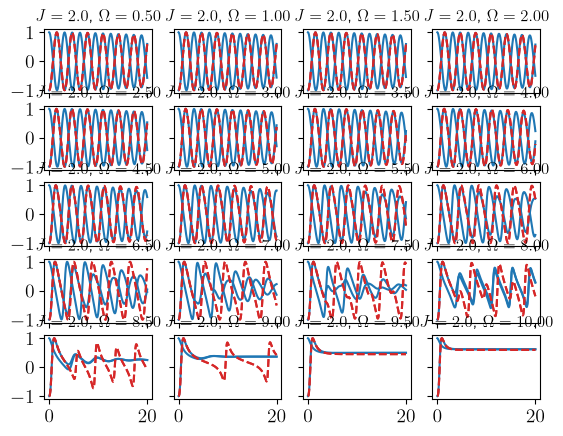

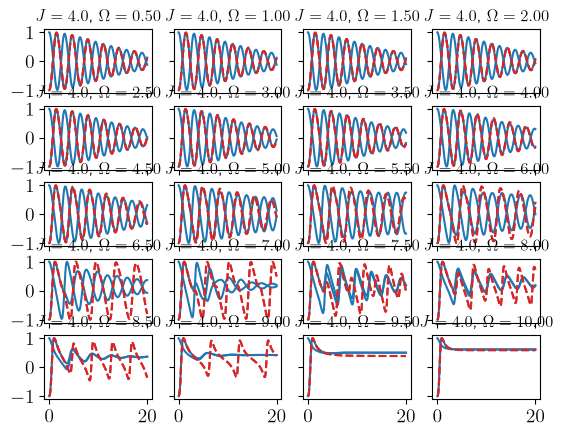

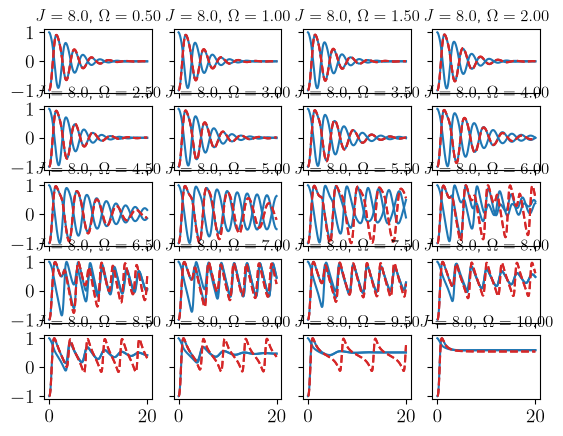

In [5]:
omega_list = np.linspace(0.5,10,20)
J_list = np.array([2.0,4.0,8.0])
Z01 = embedded_pauli('z',0,1)
tf = 20
nstep = 400
rate=nstep/tf
tvec = np.linspace(0,tf,nstep+1)
N=2
h=1

e_evo = [embed_on_site(Z01,j,N) for j in range(N)]
e_evo_eff = [embed_on_site(qt.sigmaz(),j,N,d=2) for j in range(N)]
data_dict=dict()

for J in J_list:
    fig, ax = plt.subplots(ncols=4,nrows=5,sharex=True, sharey=True)
    for iom, Omega in enumerate(omega_list):

        #--- full Hamiltonian with measurements
        single_body_terms = [[h, ('x', 0, 1), None],[Omega, ('x', 1, 2), None] ]
        two_body_terms=[[J,('x', 1, 2), ('x', 1, 2)]]
        H_qutrit = build_hamiltonian(N,single_body_terms, two_body_terms)
        
        #--- target effective Hamiltonian
        heff, lambda1, lambda2 = h, -1j*Omega**2/rate/4, -1j*J**2/rate/4
        print(f"effective paramters: lambda_1={lambda1:.2f}, lambda_2={lambda2:.2f}")
        single_body_eff = [[heff, ('x', 0, 1), None], [2*lambda1, ('p-', 0, 1), None] ]
        two_body_eff=[[2*lambda2,('p-', 0, 1), ('p-', 0, 1)]]
        H_qeff = build_hamiltonian(N,single_body_eff, two_body_eff,d=2)
    
        psi0 = qt.basis([3]*N,n=[0,1]*(N//2))
        psi0_eff = qt.basis([2]*N,n=[0,1]*(N//2))
    
        options={'progress':False}
        
        res = time_evo(H_qutrit,psi0,tvec,P,N,measured_sites=[j for j in range(N)],e_ops=e_evo, 
                       force_proj=True,options=options)
    
        res2 = time_evo(H_qeff,psi0_eff,tvec,P,N,measured_sites=[],e_ops=e_evo_eff, options=options)
        data_dict['qutrit', J, Omega] = res.expect
        data_dict['eff', J, Omega] = res2.expect
        ax[iom//4,np.mod(iom,4)].set_title(rf"$J={J:.1f}$, $\Omega={Omega:.2f}$")
        ax[iom//4,np.mod(iom,4)].plot(tvec,np.array(res.expect[0::2]).mean(axis=0),label='U-PS',c='C0')
        ax[iom//4,np.mod(iom,4)].plot(tvec,np.array(res.expect[1::2]).mean(axis=0),label='U-PS',c='C0')
        ax[iom//4,np.mod(iom,4)].plot(tvec,np.array(res2.expect[1::2]).mean(axis=0),'--',label='U-PS',c='C3')
        ax[iom//4,np.mod(iom,4)].plot(tvec,np.array(res2.expect[1::2]).mean(axis=0),'--',label='U-PS',c='C3')
        data_dict['err',J, Omega] = np.abs(np.array(res.expect)-np.array(res2.expect)).sum(axis=0)

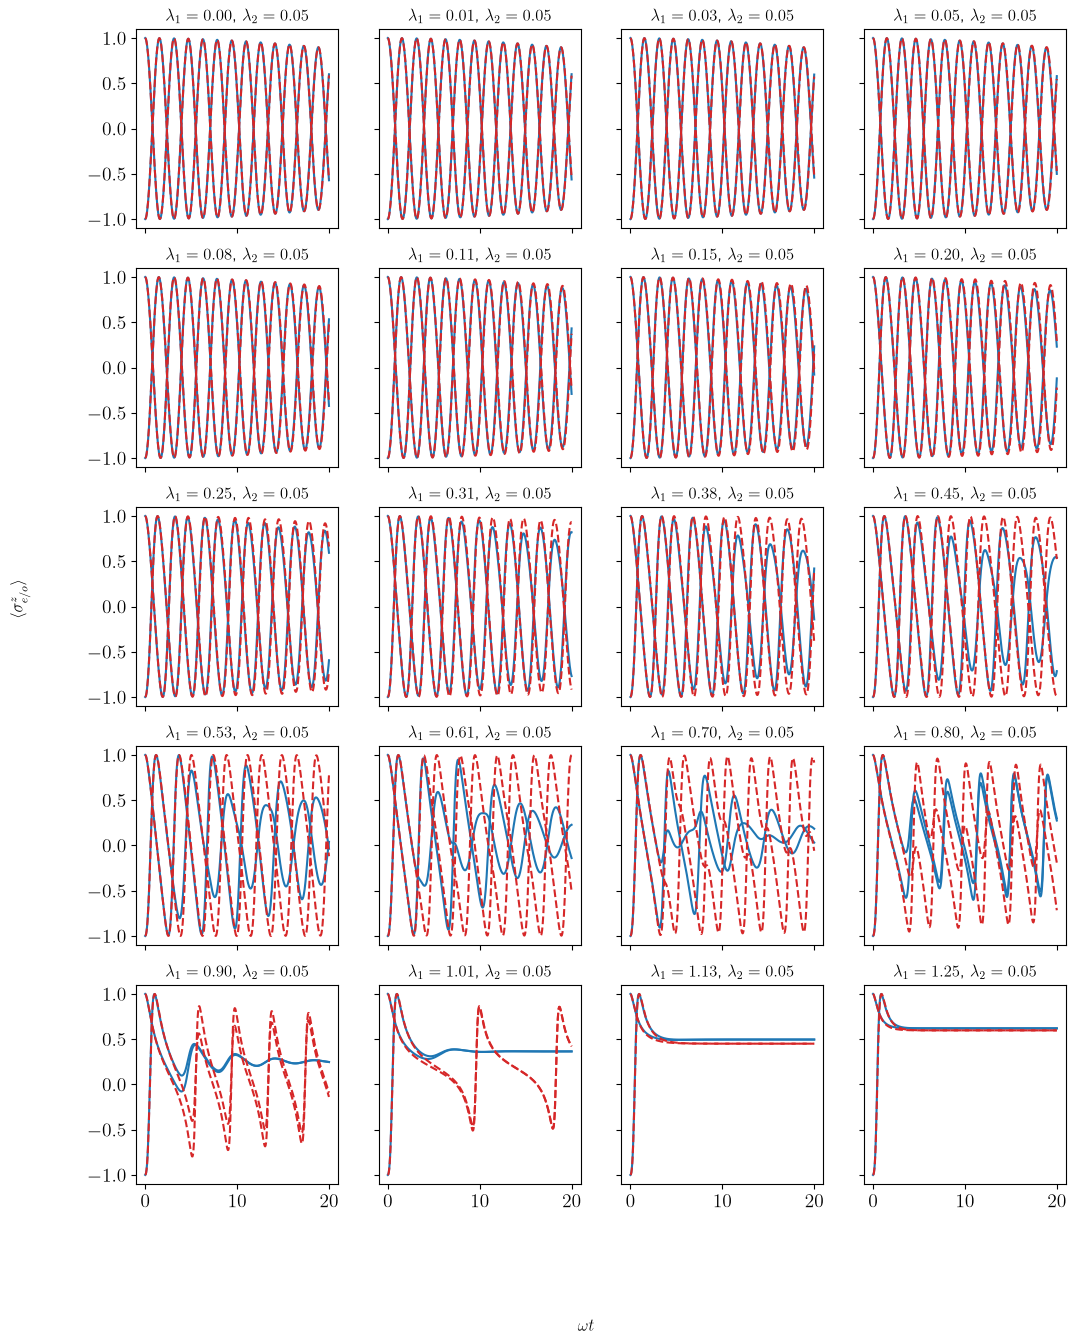

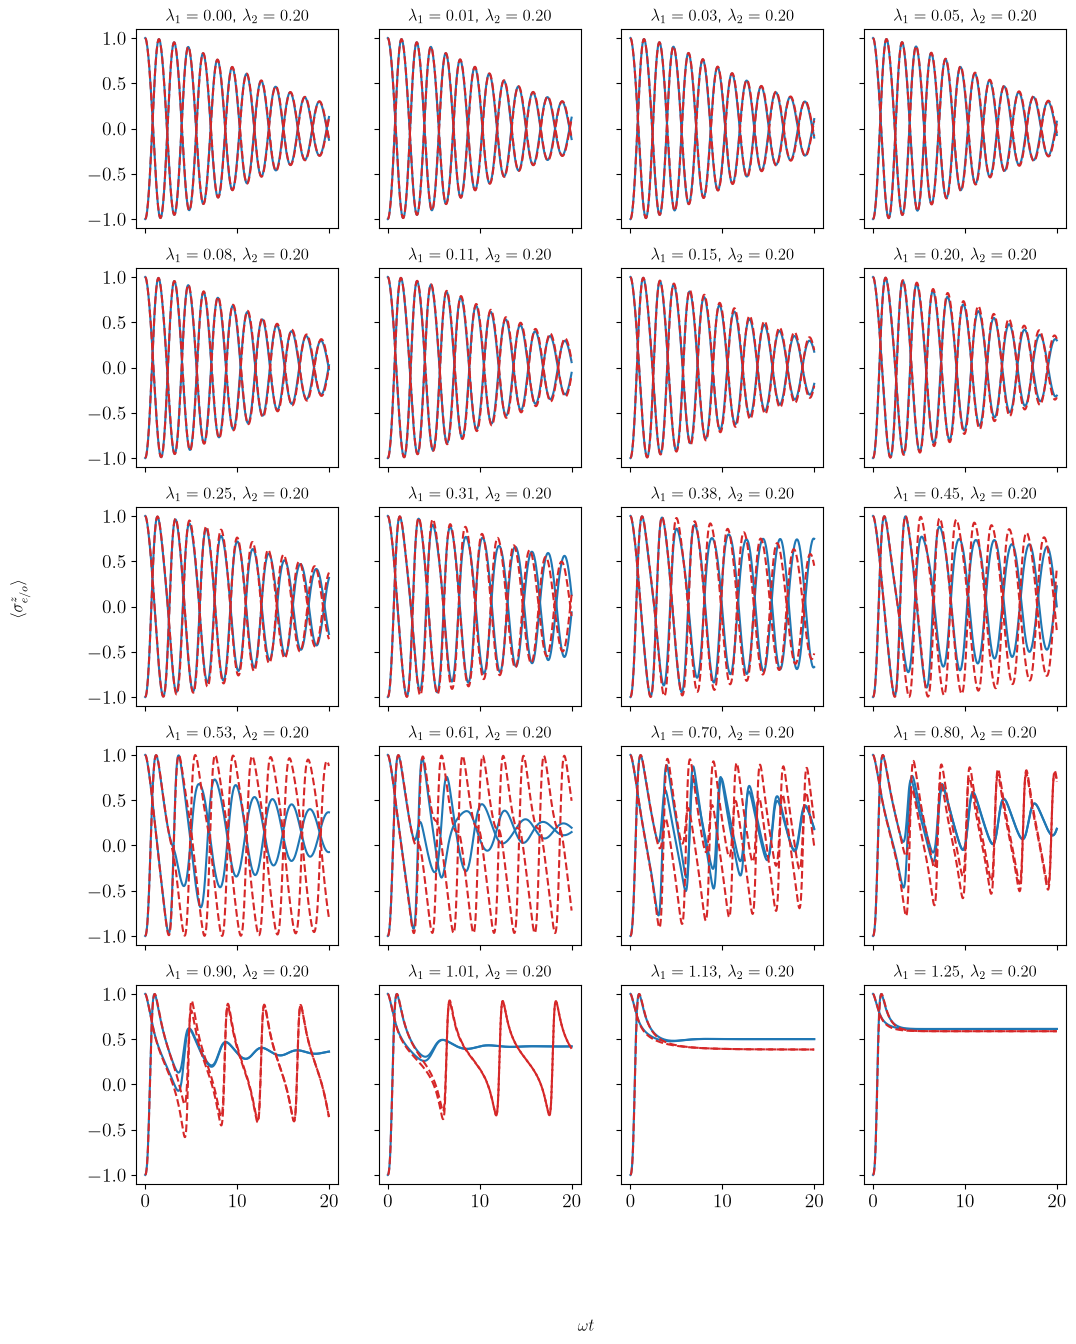

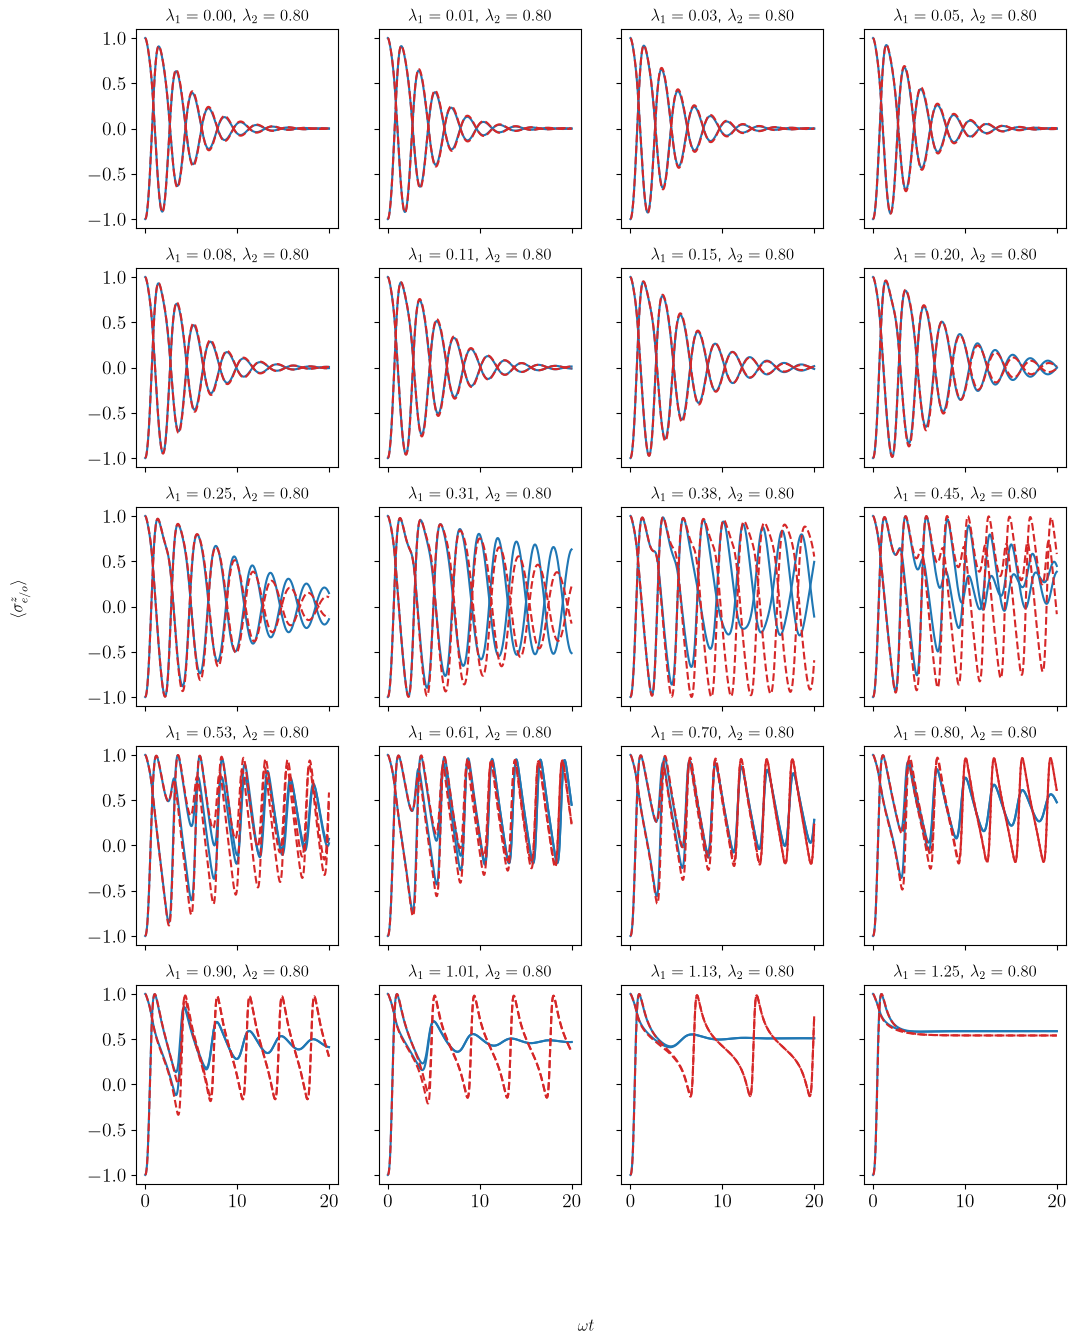

In [6]:
omega_list = np.linspace(0.5,10,20)
J_list = np.array([2.0,4.0,8.0])
Z01 = embedded_pauli('z',0,1)
tf = 20
nstep = 400
rate=nstep/tf
tvec = np.linspace(0,tf,nstep+1)
N=2
h=1


for J in J_list:
    fig, ax = plt.subplots(ncols=4,nrows=5,sharex=True, sharey=True)
    fig.set_size_inches([12,15])
    for iom, Omega in enumerate(omega_list):
        lambda1, lambda2 = Omega**2/rate/4, J**2/rate/4
        ax[iom//4,np.mod(iom,4)].set_title(rf"$\lambda_1={lambda1:.2f}$, $\lambda_2={lambda2:.2f}$")
        ax[iom//4,np.mod(iom,4)].plot(tvec,np.array(data_dict['qutrit', J, Omega][0::2]).mean(axis=0),label='U-PS',c='C0')
        ax[iom//4,np.mod(iom,4)].plot(tvec,np.array(data_dict['qutrit', J, Omega][1::2]).mean(axis=0),label='U-PS',c='C0')
        ax[iom//4,np.mod(iom,4)].plot(tvec,np.array(data_dict['eff', J, Omega][0::2]).mean(axis=0),'--',label='U-PS',c='C3')
        ax[iom//4,np.mod(iom,4)].plot(tvec,np.array(data_dict['eff', J, Omega][1::2]).mean(axis=0),'--',label='U-PS',c='C3')
        fig.supxlabel(r'$\omega t$')
        fig.supylabel(r'$\langle \sigma^z_{e/o} \rangle$')

        #fig.savefig(f'comparison_N{N}_rate{rate:.2f}.pdf',bbox_inches='tight')

                      


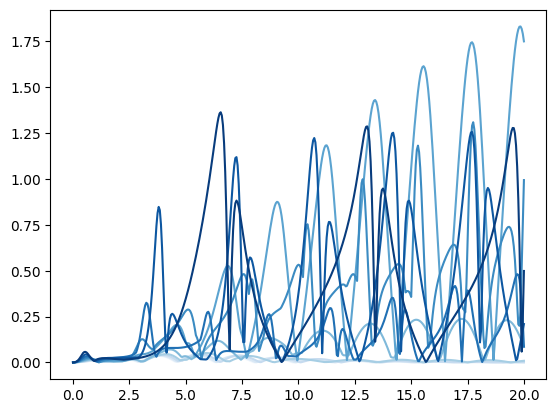

In [21]:
col = plt.cm.Blues(omega_list/max(omega_list))
J=8.0
for iom, omega in enumerate(omega_list[::2]):
    plt.plot(tvec, data_dict['err',J, omega],c=col[2*iom])

### Comparison between system sizes: entanglement

2 1
4 2
6 1
8 1
10 1
12 1


Text(0, 0.5, '$S_{\\rm ent}(N/2)$')

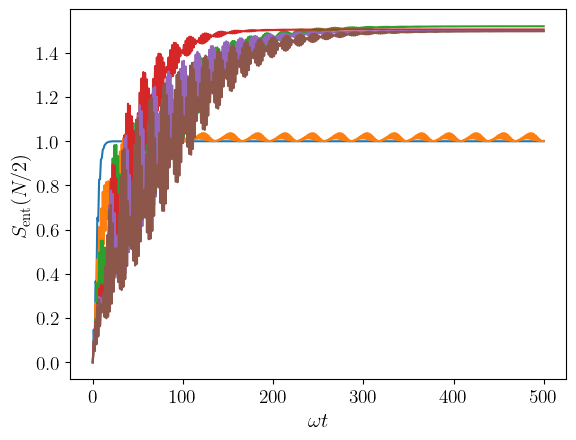

In [26]:
Omega = 4.0
Z01 = embedded_pauli('z',0,1)
tf = 500
nstep = 500
rate=nstep/tf
tvec = np.linspace(0,tf,nstep+1)
N_list=[2,4,6,8,10,12]
h=1
lambda1=0.2
lambda2=0.8
#data_dict=dict()
opts={'progress':False}
for N in N_list:
    #--- full Hamiltonian with measurements
    e_evo_eff = [embed_on_site(qt.sigmaz(),j,N,d=2) for j in range(N)]
    single_body_eff = [[h, ('x', 0, 1), None], [-2j*lambda1, ('p-', 0, 1), None] ]
    two_body_eff=[[-2j*lambda2,('p-', 0, 1), ('p-', 0, 1)]]
    H_qeff = build_hamiltonian(N,single_body_eff, two_body_eff,d=2)
    res_nh = nh_stationary_states(H_qeff,N, tol=1e-8,d=2)
    psi0_eff = qt.basis([2]*N,n=[0,1]*(N//2))
    print(N, res_nh.degeneracy)
    options={'progress':False}

    res2 = time_evo(H_qeff,psi0_eff,tvec,P,N,measured_sites=[],e_ops=e_evo_eff,options=opts)
    data_dict['eff', N, lambda1, lambda2] = res2.expect
    data_dict['ent', N, lambda1, lambda2] = res2.entanglement
    data_dict['sse', N, lambda1, lambda2] =res_nh.entanglement_entropies
    plt.plot(tvec, res2.entanglement/np.log(2),label=rf'$N={N}$')

    
plt.xlabel(r'$\omega t$')
plt.ylabel(r"$S_{\rm ent}(N/2)$" )

Text(0, 0.5, '$\\langle \\sigma^z \\rangle $')

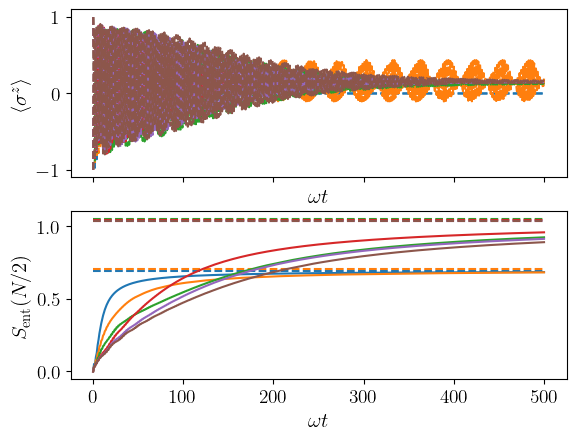

In [27]:
fig,ax=plt.subplots(nrows=2,sharex=True)
N_list=[2,4,6,8,10,12]
clist=['C0','C1','C2','C3','C4','C5']
ent_pippo=[]
for ni, N in enumerate(N_list[:]):
    ax[0].plot(tvec,np.array(data_dict['eff', N,lambda1,lambda2][0::2]).mean(axis=0),'--',label=rf'$N={N}$',
               c=clist[ni])
    ax[0].plot(tvec,np.array(data_dict['eff', N,lambda1,lambda2][1::2]).mean(axis=0),'--',
               c=clist[ni])
    
    #ax[1].plot(tvec,data_dict['ent',N,lambda1,lambda2],c=clist[ni])
    ax[1].plot(tvec,data_dict['ent',N,lambda1,lambda2].cumsum()/np.arange(1,nstep+2),c=clist[ni])
    ent_pippo.append((data_dict['ent',N,lambda1,lambda2].cumsum()/np.arange(1,nstep+2))[-1])
    ax[1].plot(tvec,tvec*0+np.array(data_dict['sse',N,lambda1,lambda2]).mean(),'--', c=clist[ni])
ax[0].set_xlabel(r'$\omega t$')
ax[1].set_xlabel(r'$\omega t$')
ax[1].set_ylabel(r"$S_{\rm ent}(N/2)$" )
ax[0].set_ylabel(r"$\langle \sigma^z \rangle $" )

In [7]:
plt.plot(N_list,[data_dict['sse',N,lambda1,lambda2] for N in N_list],'.-')
plt.plot(N_list,0.5+np.log(np.array(N_list)**0.2),'.-')

plt.semilogx()

NameError: name 'N_list' is not defined

In [29]:
np.save(f'data_long_time.npy',data_dict,allow_pickle=True)

[]

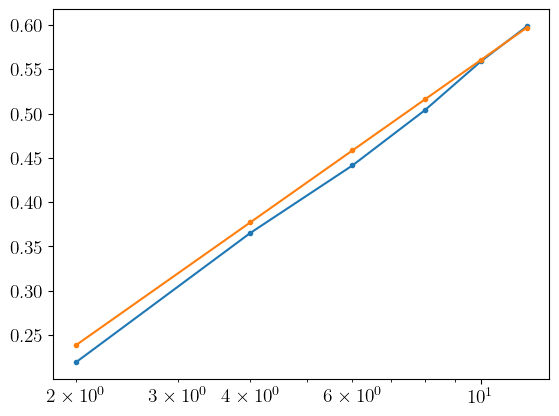

In [62]:
plt.plot(N_list,ent_pippo,'.-')
plt.plot(N_list,0.1+0.2*np.log(np.array(N_list)),'.-')

plt.semilogx()

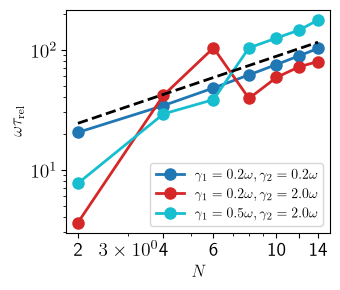

In [4]:

# Load the data
data = np.loadtxt('relaxation_rates.csv', delimiter=',', skiprows=0)
N_vals = data[:, 0].astype(int)
lambda1_vals = data[:, 1]
lambda2_vals = data[:, 2]
relaxation_rates = data[:, 3]

# Get unique (lambda1, lambda2) pairs
unique_points = np.unique(np.column_stack([lambda1_vals, lambda2_vals]), axis=0)

# Create figure
fig, ax = plt.subplots(figsize=(3.5, 3))


# Colors for different points
colors = plt.cm.tab10(np.linspace(0, 1, len(unique_points)))

# Plot data for each (lambda1, lambda2) point
for idx, (lam1, lam2) in enumerate(unique_points):
    if lam2 == 2.25:
        continue
    mask = (lambda1_vals == lam1) & (lambda2_vals == lam2)
    N_subset = N_vals[mask]
    rate_subset = relaxation_rates[mask]
    
    # Sort by N for proper plotting
    sort_idx = np.argsort(N_subset)
    N_subset = N_subset[sort_idx]
    rate_subset = rate_subset[sort_idx]
    
    ax.plot(N_subset, 1/rate_subset, 'o-', color=colors[idx], 
            label=rf'$\gamma_1={2*lam1:.1f}\omega, \gamma_2={2*lam2:.1f}\omega$', linewidth=2, markersize=8)

ax.plot(N_subset,14*N_subset**(0.8),'k--',lw=2)
ax.set_xlabel(r'$N$', fontsize=12)
ax.set_ylabel(r'$\omega \tau_{\rm rel}$', fontsize=12)
#ax.set_title(r'Relaxation rate vs system size', fontsize=14)
ax.loglog()
ax.legend(fontsize=10, loc='best')
#ax.grid(True, alpha=0.3)
ax.set_xticks([2,4,6,10,12,14],labels=["2", "4", "6", "10"," ", "14"])

fig.tight_layout()
#fig.savefig('relaxation_rates.pdf', bbox_inches='tight')
plt.show()

## skin effect

In [49]:
heff = 1
N=8

single_body_eff = [[-0.5j*heff, ('p-', 0, 1),0]]

for j in range(1,N-1):
    single_body_eff.append([-1j*heff, ('p-', 0, 1), j]) 
    
single_body_eff.append([-0.5j*heff, ('p-', 0, 1), N-1]) 
two_body_eff=[[-1j*0,('p-', 0, 1), ('p-', 0, 1)], [heff, ('-',0,1),('+',0,1)]]
#single_body_eff=[]
H_qeff = build_hamiltonian(N,single_body_eff, two_body_eff,d=2)
e_evo_eff = [embed_on_site(qt.sigmaz(),j,N,d=2) for j in range(N)]

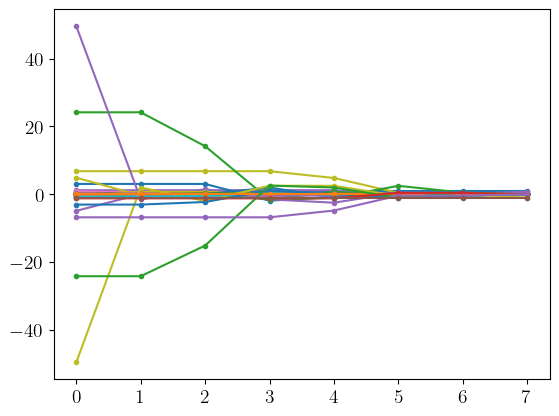

In [76]:
N=4
h, J, Omega= 1,7.2, 4.5
tf = 20
nstep = 200
tvec = np.linspace(0,tf,nstep+1)
rate = nstep/tf
dt = tvec[1]
#--- full Hamiltonian with measurements
single_body_terms = [[h, ('x', 0, 1), None],[Omega, ('x', 1, 2), None] ]
two_body_terms=[[J,('x', 1, 2), ('x', 1, 2)]]
H_qutrit = build_hamiltonian(N,single_body_terms, two_body_terms)

#U_qutrit = qt.tensor([P]*N)*qt.propagator(H_qutrit,dt)

#--- target effective Hamiltonian
heff, lambda1, lambda2 = h, -1j*Omega**2/rate/4, -1j*J**2/rate/4
print(f"effective paramters: lambda_1={lambda1:.2f}, lambda_2={lambda2:.2f}")
single_body_eff = [[heff, ('x', 0, 1), None], [2*lambda1, ('p-', 0, 1), None] ]
two_body_eff=[[2*lambda2,('p-', 0, 1), ('p-', 0, 1)]]
H_qeff = build_hamiltonian(N,single_body_eff, two_body_eff,d=2)
U_qeff = qt.propagator(H_qeff,dt)

out = compare_dt_expansion(H_qutrit, N, [dt], d=d)

effective paramters: lambda_1=-0.00-0.51j, lambda_2=-0.00-1.30j


In [77]:
#Eu_qutrit, Su_qutrit = U_qutrit.eigenstates()
Eu_qeff, Su_qeff = U_qeff.eigenstates()

#filt = np.abs(Eu_qutrit.real)>1e-10

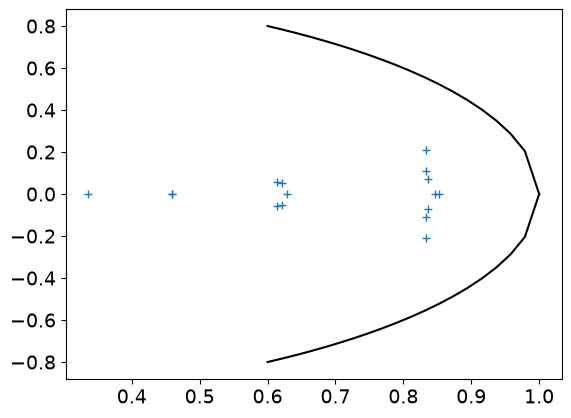

In [78]:
#plt.plot(Eu_qutrit[filt].real,Eu_qutrit[filt].imag,'o')
plt.plot(Eu_qeff.real,Eu_qeff.imag,'+')
x=np.linspace(0.6,1,20)
plt.plot(x,np.sqrt(1-x**2),'k')
plt.plot(x,-np.sqrt(1-x**2),'k')


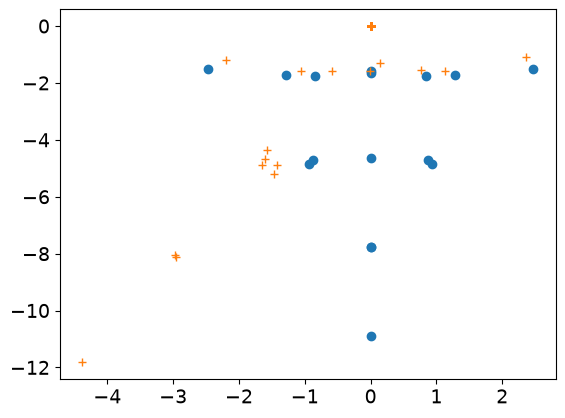

In [79]:

E_qeff, S_qeff = H_qeff.eigenstates()

E_qeff2, S_qeff2 = (out['H_PP'] - 1j *dt/2*out['M'] - dt**2/6*(out['N']+ out['M']*out['H_PP']+out['H_PP']*out['M'])).eigenstates()
plt.plot(E_qeff.real,E_qeff.imag,'o')
plt.plot(E_qeff2.real,E_qeff2.imag,'+')

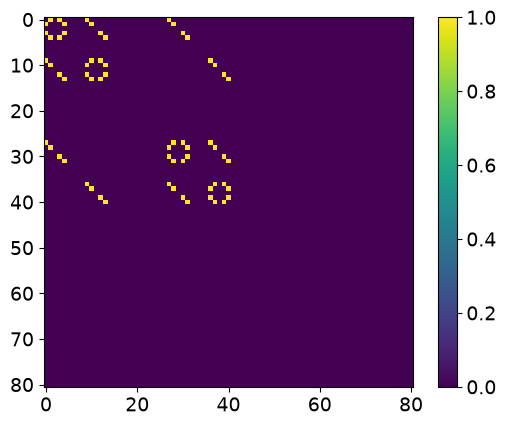

In [82]:
#plt.imshow((out['M']*out['H_PP']+out['H_PP']*out['M']).full().real)
plt.imshow(out['H_PP'].full().real)
plt.colorbar()

In [40]:



def compare_dt_expansion(H_full, N,  dts, d=3, rho0=None):
    """
    Compare the exact projected propagation of rho0 under H_full against the
    O(dt^2) and O(dt^3) truncated non-Hermitian expansions.

    Parameters
    ----------
    H_full : qt.Qobj
        Full N-qudit Hamiltonian (e.g. from build_hamiltonian).
    N : int
        Number of qudits.
    rho0 : qt.Qobj
        Initial density matrix, must satisfy P rho0 P = rho0 (i.e. live
        entirely in the computational subspace {0,...,d-2} of every site).
    dts : array-like
        List/array of time steps to test.
    d : int
        Local Hilbert space dimension (default 3; auxiliary level = d-1).

    Returns
    -------
    dict with keys:
        'dts'   : the input time steps
        'res2'  : ||exact - order2|| for each dt   (O(dt^2) truncation)
        'res3'  : ||exact - order3|| for each dt   (O(dt^3) truncation)
        'slope2', 'slope3' : local log-log scaling exponents (expect ~3, ~4)
        'H_PP', 'M', 'N' : the operators entering the expansion, for reuse
    """
    dts = np.asarray(dts, dtype=float)

    # --- global P / Q projectors -----------------------------------------
    Pg = qt.tensor([P] * N)
    Qg = qt.qeye(Pg.dims[0]) - Pg

    if rho0 is not None:
        if (Qg * rho0).norm() > 1e-10:
            raise ValueError("rho0 is not fully contained in the P subspace "
                              "(||Q rho0|| too large).")

    # --- block operators ---------------------------------------------------
    H_PP = Pg * H_full * Pg
    H_PQ = Pg * H_full * Qg
    H_QP = Qg * H_full * Pg
    H_QQ = Qg * H_full * Qg

    M = H_PQ * H_QP                 # -> H_n.h. = -i (dt/2) M      [Eq. 3-4]
    Nop = H_PQ * H_QQ * H_QP        # new O(dt^3) block

    def comm(A, B):
        return A * B - B * A

    def order2_nh(dt, rho = None):
        Hnh = H_PP -1j*dt/2 * M
        Unh = (-1j * Hnh * dt).expm()
        if rho is None:
            return Unh
        else: 
            Udag = (1j * Hnh * dt).expm()
            return Unh * rho * Udag

        
    def order2(dt, rho):
        
        dvn = comm(H_PP, comm(H_PP, rho))
        return rho - 1j * dt * comm(H_PP, rho) \
                   - dt**2 / 2 * dvn \
                   - dt**2 / 2 * (M * rho + rho * M)

    def order3(dt, rho):
        cubic_vn = comm(H_PP, comm(H_PP, comm(H_PP, rho)))
        cubic_MN = comm(Nop, rho) + comm(H_PP * M + M * H_PP, rho) \
                   + 3 * (H_PP * rho * M - M * rho * H_PP)
        return order2(dt, rho) + (1j * dt**3 / 6) * (cubic_vn + cubic_MN)

    def exact(dt, rho=None):
        if rho is None:
            return Pg*qt.propagator(H_full,dt)
        else:
            U = (-1j * H_full * dt).expm()
            return Pg * (U * rho * U.dag()) * Pg
    
    res2, res3 = [], []

    if rho0 is  None:
        for dt in dts:
            ex = Pg*(-1j * H_full * dt).expm()*Pg
            res2.append((Pg*order2_nh(dt)*Pg-ex).norm())
        res2 = np.array(res2)
    else:
        for dt in dts:
            ex = exact(dt, rho0)
            res2.append((ex - order2_nh(dt, rho0)).norm())
            res3.append((ex - order3(dt, rho0)).norm())
        res2, res3 = np.array(res2), np.array(res3)
    
    def slopes(res):
        return np.log(res[:-1] / res[1:]) / np.log(dts[:-1] / dts[1:])

    return {
        'dts': dts,
        'res2': res2,
        'res3': res3,
        'slope2': slopes(res2),
        #'slope3': slopes(res3),
        'H_PP': H_PP, 'M': M, 'N': Nop,
    }



In [28]:
def compare_propagator_expansion(H_full, N, dts, d=3):
    """
    Confronta il propagatore proiettato esatto K_exact(dt) = P exp(-i dt H_full) P
    con le sue troncature a O(dt), O(dt^2), O(dt^3).

    Parametri
    ---------
    H_full : qt.Qobj
        Hamiltoniana completa a N quditi (es. da build_hamiltonian).
    N : int
        Numero di quditi.
    dts : array-like
        Passi temporali da testare.
    d : int
        Dimensione dello spazio di Hilbert locale (default 3; livello
        ausiliario = d-1).

    Ritorna
    -------
    dict con chiavi:
        'dts'                  : i passi temporali in input
        'res1', 'res2', 'res3' : ||K_exact - K_orderN|| per ogni dt
        'slope1','slope2','slope3' : esponenti di scaling log-log locali
                                      (attesi ~2, ~3, ~4)
        'H_PP', 'M', 'N'       : gli operatori a blocchi usati nell'espansione
    """
    dts = np.asarray(dts, dtype=float)

    # --- proiettori globali P / Q ------------------------------------------
    Qloc = qt.Qobj(np.diag([0.0] * (d - 1) + [1.0]))
    Ploc = qt.qeye(d) - Qloc
    Pg = qt.tensor([Ploc] * N)
    Qg = qt.qeye(Pg.dims[0]) - Pg

    # --- operatori a blocchi -------------------------------------------------
    H_PP = Pg * H_full * Pg
    H_PQ = Pg * H_full * Qg
    H_QP = Qg * H_full * Pg
    H_QQ = Qg * H_full * Qg

    M = H_PQ * H_QP                 # entra in K a O(dt^2); H_n.h. = -i dt M/2
    Nop = H_PQ * H_QQ * H_QP        # entra in K solo a O(dt^3)

    def K_exact(dt):
        return Pg * (-1j * dt * H_full).expm() * Pg

    def K_order1(dt):
        return Pg - 1j * dt * H_PP

    def K_order2(dt):
        return K_order1(dt) - dt**2 / 2 * (H_PP * H_PP + M)

    def K_order3(dt):
        H3_PP = H_PP * H_PP * H_PP + H_PP * M + M * H_PP + Nop
        return K_order2(dt) + 1j * dt**3 / 6 * H3_PP

    res1, res2, res3 = [], [], []
    for dt in dts:
        Ke = K_exact(dt)
        res1.append((Ke - K_order1(dt)).norm())
        res2.append((Ke - K_order2(dt)).norm())
        res3.append((Ke - K_order3(dt)).norm())
    res1, res2, res3 = np.array(res1), np.array(res2), np.array(res3)

    def slopes(res):
        return np.log(res[:-1] / res[1:]) / np.log(dts[:-1] / dts[1:])

    return {
        'dts': dts,
        'res1': res1, 'res2': res2, 'res3': res3,
        'slope1': slopes(res1), 'slope2': slopes(res2), 'slope3': slopes(res3),
        'H_PP': H_PP, 'M': M, 'N': Nop,
    }

In [41]:

N, d = 2, 3
omega, Omega, J = 1.0, 0.01, 0.01
H_full = build_hamiltonian(
    N,
    single_body_terms=[[omega, ('x', 0, 1), None],
                        [Omega, ('x', 1, 2), None]],
    two_body_terms=[[J, ('x', 1, 2), ('x', 1, 2)]],
    boundary='OBC', d=d,
)

Pg = qt.tensor([P]*N)
np.random.seed(1)
psi0 = (Pg * qt.rand_ket(dimensions=[3] * N)).unit()
rho0 = psi0 * psi0.dag()

dts = np.linspace(0.05,0.2,40)
dts = [0.1]
res, err = [],[]
dt=dts[0]
lam1_vec=np.linspace(0,5,21)
lam2_vec=np.linspace(0,5,21)

for Omega in np.sqrt(2*lam1_vec/dt):
    for J in np.sqrt(2*lam2_vec/dt):
        H_full = build_hamiltonian(
        N,
        single_body_terms=[[omega, ('x', 0, 1), None],
                            [Omega, ('x', 1, 2), None]],
        two_body_terms=[[J, ('x', 1, 2), ('x', 1, 2)]],
        boundary='OBC', d=d,
        )
        psi0 = (Pg * qt.rand_ket(dimensions=[3] * N)).unit()
        rho0 = psi0 * psi0.dag()
        out = compare_dt_expansion(H_full, N, dts, d=d)
        res.append(out['res2'])
        err.append(dt**2*out['M'].tr()/2**N)


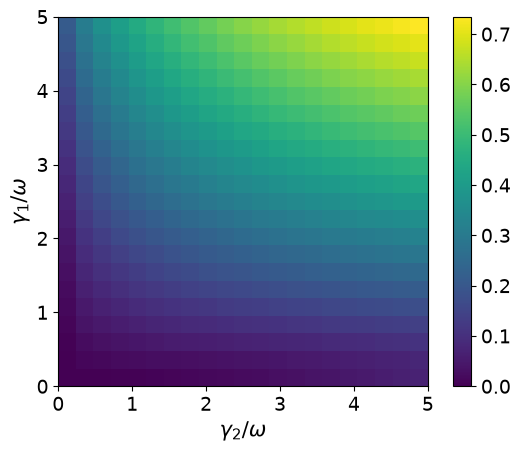

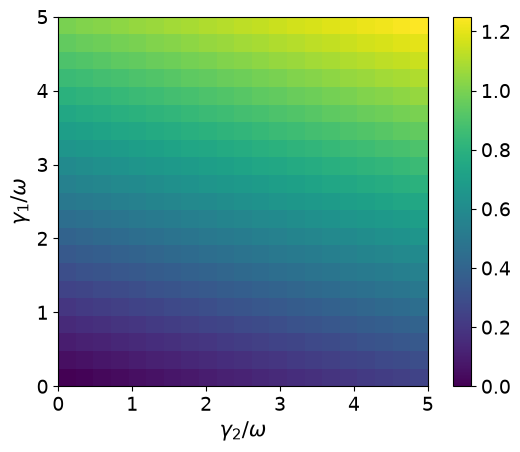

In [42]:
plt.imshow(((np.abs(np.array(res).reshape([21,21])))),extent=[0,5,0,5],origin='lower')
plt.ylabel(r'$\gamma_1/\omega$')
plt.xlabel(r'$\gamma_2/\omega$')
plt.colorbar()

plt.figure()
plt.imshow(np.array(err).reshape([21,21]),extent=[0,5,0,5],origin='lower')
plt.ylabel(r'$\gamma_1/\omega$')
plt.xlabel(r'$\gamma_2/\omega$')
plt.colorbar()



In [54]:
dts = np.linspace(0.01,0.2,40)
omega, Omega,J = 2,0.8, 7.5
N=2
H_full = build_hamiltonian(
N,
single_body_terms=[[omega, ('x', 0, 1), None],
                    [Omega, ('x', 1, 2), None]],
two_body_terms=[[J, ('x', 1, 2), ('x', 1, 2)]],
boundary='OBC', d=d,
)
#psi0 = (Pg * qt.rand_ket(dimensions=[3] * N)).unit()
rho0 = psi0 * psi0.dag()
out = compare_dt_expansion(H_full, N, dts, d=d)


ValueError: x and y must have same first dimension, but have shapes (40,) and (1,)

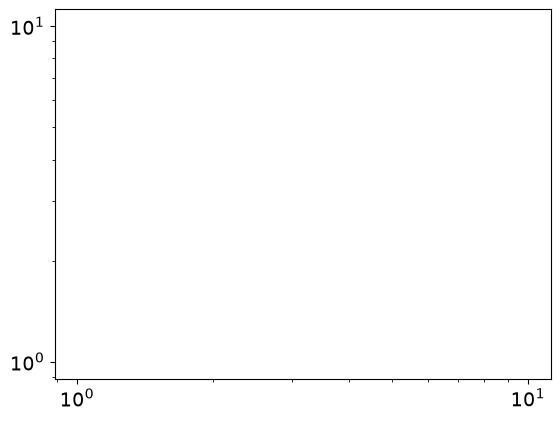

In [83]:
plt.loglog(dts,(out['res2']))
#plt.loglog(dts,out['M'].tr()*dts**2)
#plt.loglog(dts,dts**2)
#plt.loglog(dts,dts**4)
plt.loglog(dts,dts**3)

#plt.loglog(dts,out['M'].tr()*dts**2-2**N+np.abs(out['res2']),'k--')
#plt.loglog(dts,-np.imag(out['res2']),'b-.')


In [84]:

from scipy.linalg import expm
sx=np.array([[0,1],[1,0]]);n=np.diag([0,1.]);I=np.eye(2)
def H(g1,g2): 
    return np.kron(sx,I)+np.kron(I,sx)-1j*g1*(np.kron(n,I)+np.kron(I,n))-1j*g2*np.kron(n,n)
nn=np.kron(n,n)
dt=0.05
for lab,g1 in [("E",0.025),("D",1.6),("S",2.5)]:
    He=H(g1,1.6); psi=np.array([0,1,0,0],complex); U=expm(-1j*dt*He); w=[]
    for _ in range(int(20/dt)):
        psi=U@psi; psi/=np.linalg.norm(psi); w.append(np.vdot(psi,nn@psi).real)
    J=8; coef=2*g1*J*dt
    print(f"{lab}: Ising coeff 2g1 J dt = {coef:.3f} w ; time-avg <n1 n2> = {np.mean(w):.4f} ; product = {coef*np.mean(w):.4f}")


E: Ising coeff 2g1 J dt = 0.020 w ; time-avg <n1 n2> = 0.0110 ; product = 0.0002
D: Ising coeff 2g1 J dt = 1.280 w ; time-avg <n1 n2> = 0.0756 ; product = 0.0967
S: Ising coeff 2g1 J dt = 2.000 w ; time-avg <n1 n2> = 0.0251 ; product = 0.0503


In [85]:
1/0.05**2

399.99999999999994

In [87]:
400*np.exp(1*4)

np.float64(21839.260013257695)

In [89]:
np.exp(1)**4

np.float64(54.59815003314423)

In [90]:
import numpy as np, qutip as qt, sys, io, contextlib
from scipy.linalg import expm, eigvals
sys.path.insert(0,'/home/claude')
with contextlib.redirect_stdout(io.StringIO()):
    from qudit_nh_design import build_hamiltonian

def setup(N, w, Om, J):
    H = build_hamiltonian(N,[[w,('x',0,1),None],[Om,('x',1,2),None]],
                          [[J,('x',1,2),('x',1,2)]],boundary='OBC',d=3).full()
    Pdiag = np.array(qt.tensor([qt.Qobj(np.diag([1.,1.,0.]))]*N).full().diagonal().real)
    idx = np.where(Pdiag>0.5)[0]; jdx = np.where(Pdiag<0.5)[0]
    return H, idx, jdx

def blocks(H, idx, jdx):
    HPP=H[np.ix_(idx,idx)]; HPQ=H[np.ix_(idx,jdx)]; HQQ=H[np.ix_(jdx,jdx)]
    M=HPQ@HPQ.conj().T; Nop=HPQ@HQQ@HPQ.conj().T
    return HPP,M,Nop

def ops_P(N):
    # sigma^x and n on the qubit (P) space, ordering consistent with idx (|0>,|1> per site)
    sx=np.array([[0,1],[1,0]]); n=np.diag([0,1]); I=np.eye(2)
    def site(o,j):
        out=np.array([[1.]])
        for k in range(N): out=np.kron(out, o if k==j else I)
        return out
    return [site(sx,j) for j in range(N)], [site(n,j) for j in range(N)]

def slow_two(eps):
    im=np.sort(eps.imag)[::-1]          # least negative first
    return im[0], im[1], im[0]-im[1]

def analyse(N, w, g1, g2, dt, verbose=False):
    Om=np.sqrt(2*g1/dt); J=np.sqrt(2*g2/dt)
    H,idx,jdx=setup(N,w,Om,J); HPP,M,Nop=blocks(H,idx,jdx)
    sx,n=ops_P(N)
    Heff = w*sum(sx) - 1j*g1*sum(n) - 1j*g2*sum(n[j]@n[j+1] for j in range(N-1))
    # exact quasi-energies of K = P U P
    K = expm(-1j*dt*H)[np.ix_(idx,idx)]
    epsK = 1j*np.log(eigvals(K))/dt
    epsE = eigvals(Heff)
    # corrected dH pieces
    d_w   = w*g1*dt/6*sum(sx)
    d_fac = w*g2*dt/6*sum(sx[j]@n[j+1]+n[j]@sx[j+1] for j in range(N-1))
    d_is  = -2*g1*J*dt*sum(n[j]@n[j+1] for j in range(N-1))
    out = {'K':slow_two(epsK)[2], 'Heff':slow_two(epsE)[2],
           'Heff+dH':slow_two(eigvals(Heff+d_w+d_fac+d_is))[2],
           'Heff+Ising':slow_two(eigvals(Heff+d_is))[2],
           'Heff+w,fac':slow_two(eigvals(Heff+d_w+d_fac))[2]}
    if verbose:
        print("  check: Heff from blocks == target?",
              np.allclose(HPP-1j*dt*M/2, Heff))
        print("  eps(Heff) sorted by Im:", np.round(sorted(epsE,key=lambda z:-z.imag),4))
        print("  eps(K)    sorted by Im:", np.round(sorted(epsK,key=lambda z:-z.imag),4))
    return out

print("=== N=2, Fig.3 D point: g1=g2=1.6, w dt=0.05 ===")
r=analyse(2,1.0,1.6,1.6,0.05,verbose=True); print(r)

for N,g1,g2 in [(2,1.6,1.6),(4,1.25,2.45)]:
    print(f"\n=== splitting delta = Im e0 - Im e1 vs dt  (N={N}, g1={g1}, g2={g2}) ===")
    print(f"{'w dt':>8}{'K exact':>12}{'Heff':>12}{'Heff+dH':>12}{'+Ising only':>13}{'+w,fac only':>13}")
    for dt in [0.1,0.05,0.025,0.0125,0.00625,0.003125]:
        r=analyse(N,1.0,g1,g2,dt)
        print(f"{dt:8.5f}{r['K']:12.5f}{r['Heff']:12.2e}{r['Heff+dH']:12.5f}{r['Heff+Ising']:13.5f}{r['Heff+w,fac']:13.5f}")


=== N=2, Fig.3 D point: g1=g2=1.6, w dt=0.05 ===
  check: Heff from blocks == target? True
  eps(Heff) sorted by Im: [-1.0202-1.131j  1.0202-1.131j  0.    -1.6j   -0.    -4.138j]
  eps(K)    sorted by Im: [-0.8951-1.0492j  1.1601-1.1385j -0.    -1.6442j -1.7728-4.332j ]
{'K': np.float64(0.08934074695542216), 'Heff': np.float64(4.440892098500626e-16), 'Heff+dH': np.float64(0.07720289824871318), 'Heff+Ising': np.float64(0.07567565169231227), 'Heff+w,fac': np.float64(4.440892098500626e-16)}

=== splitting delta = Im e0 - Im e1 vs dt  (N=2, g1=1.6, g2=1.6) ===
    w dt     K exact        Heff     Heff+dH  +Ising only  +w,fac only
 0.10000     0.13568    4.44e-16     0.10637      0.10130      0.00000
 0.05000     0.08934    4.44e-16     0.07720      0.07568      0.00000
 0.02500     0.05919    4.44e-16     0.05451      0.05414      0.00000
 0.01250     0.03989    4.44e-16     0.03816      0.03809      0.00000
 0.00625     0.02736    4.44e-16     0.02674      0.02673      0.00000
 0.00313   